In [7]:
import awkward as ak
import matplotlib.pyplot as plt
import mplhep as hep
hep.style.use("CMS")

In [3]:
filename = "../data/hackathon/taus_stdCalo_PU30.parquet"
df = ak.from_parquet(filename)
df.fields

['LayerCluster',
 'TICLCand',
 'Candidate2Tracksters',
 'ticlTrackstersCLUE3DHigh',
 'ticlTracksterLinks',
 'ticlTrackstersRecovery',
 'ticlSimTracksters',
 'ticlSimTrackstersFromCPs',
 'SimTICLCand',
 'SimCandidate2Tracksters',
 'CLUE3DHighToSimTSByHits',
 'SimTSToCLUE3DHighByHits',
 'CLUE3DHighToSimTSByLCs',
 'SimTSToCLUE3DHighByLCs',
 'CLUE3DHighToSimTSCPByHits',
 'SimTSCPToCLUE3DHighByHits',
 'CLUE3DHighToSimTSCPByLCs',
 'SimTSCPToCLUE3DHighByLCs',
 'LinksToSimTSByHits',
 'SimTSToLinksByHits',
 'LinksToSimTSByLCs',
 'SimTSToLinksByLCs',
 'LinksToSimTSCPByHits',
 'SimTSCPToLinksByHits',
 'LinksToSimTSCPByLCs',
 'SimTSCPToLinksByLCs',
 'TruthCB',
 'CLUE3DHighToTruthCB',
 'TruthCBToCLUE3DHigh',
 'LayerClusterToTruthCB',
 'TruthCBToLayerCluster']

In [5]:
df.LayerCluster.fields

['LayerCluster_nHits',
 'LayerCluster_seedDetId',
 'LayerCluster_energy',
 'LayerCluster_eta',
 'LayerCluster_phi',
 'LayerCluster_x',
 'LayerCluster_y',
 'LayerCluster_z']

In [53]:
# Plot LayerClusters in eta-phi aplane for the first 2 events
for i in range(1):
    event = df[i]
    lc_eta = event.LayerCluster.LayerCluster_eta
    lc_phi = event.LayerCluster.LayerCluster_phi
    lc_energy = event.LayerCluster.LayerCluster_energy
    lc_truth_idx = event.LayerClusterToTruthCB.LayerClusterToTruthCBLinks_index
    
    plt.figure(figsize=(8, 6))

    deltaR_list = []

    print(set(lc_truth_idx))
    
    for idx_truth in set(lc_truth_idx):
        print(f"TruthCB idx: {idx_truth}")
        lc_matched_to_truth = lc_truth_idx == idx_truth

        #mask_energy = lc_energy > 0.2
        lc_eta_matched = lc_eta[lc_matched_to_truth]
        lc_phi_matched = lc_phi[lc_matched_to_truth]
        lc_energy_matched = lc_energy[lc_matched_to_truth]

        i_max = ak.argmax(lc_energy_matched)

        lc_eta_matched_max = lc_eta_matched[i_max]
        lc_phi_matched_max = lc_phi_matched[i_max]

        truth_eta = event.TruthCB.TruthCB_eta[idx_truth]
        truth_phi = event.TruthCB.TruthCB_phi[idx_truth]

        deltaR = ((lc_eta_matched_max - truth_eta)**2 + (lc_phi_matched_max - truth_phi)**2)**0.5

        deltaR_list.append(deltaR)

        print(deltaR)

        #plt.scatter(lc_phi_matched, lc_eta_matched, c=lc_energy_matched, cmap='viridis', s=10)
        #plt.scatter(truth_phi, truth_eta, c='red', marker='x', s=100, label='TruthCB')
        #plt.colorbar(label='Energy')
        plt.hist(deltaR, bins=30, alpha=0.5, label=f'TruthCB idx {idx_truth}')
        plt.xlabel('Phi')
        plt.ylabel('Eta')
        plt.title(f'LayerClusters in Eta-Phi Plane for Event {i}')
        plt.grid()
        plt.show()

{0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 69, 70, 71, 72, 73, 74, 75, 76, 77, 78, 79, 80, 81, 82, 83, 84, 86, 87, 88, 89, 90, 91, 92, 93, 94, 95, 96, 97, 98, 99, 100, 101, 102, 103, 104, 105, 106, 107, 108, 109, 110, 111, 112, 113, 114, 115, 116, 117, 118, 119, 120, 121, 122, 123, 124, 125, 126, 127, 128, 129, 130, 131, 132, 133, 134, 135, 136, 137, 138, 139, 140, 141, 142, 143, 144, 145, 146, 147, 148, 149, 150, 151, 152, 153, 154, 155, 156, 157, 158, 159, 160, 161, 162, 163, 164, 165, 166, 167, 168, 169, 170, 171, 172, 173, 174, 176, 178, 179, 180, 182, 183, 184, 185, 186, 187, 188, 189, 190, 191, 192, 193, 194, 195, 196, 197, 198, 199, 200, 201, 202, 203, 204, 205, 206, 207, 208, 209, 210, 211, 212, 213, 214, 215, 216, 217, 218, 220, 221, 222, 223, 224, 225, 226, 227, 228, 

ValueError: in NumpyArray attempting to get 48344, index out of range

(https://github.com/scikit-hep/awkward-1.0/blob/1.10.5/src/cpu-kernels/awkward_regularize_arrayslice.cpp#L14)

<Figure size 800x600 with 0 Axes>

In [58]:
df.LayerClusterToTruthCB.LayerClusterToTruthCBLinks_index[0]

<Array [867, 9, 2961, ... 1130, 1792, 1196] type='52855 * uint32'>

In [56]:
df.LayerCluster.LayerCluster_eta[0]

<Array [-2.91, -2.92, -2.9, ... 2.25, 1.54] type='40074 * float32'>

In [61]:
df.TruthCB.TruthCB_boundaryE[0]

<Array [2.11, 2.61, 3.6, ... 1.76, 2.79, 1.38] type='4050 * float32'>

In [75]:
df.LayerClusterToTruthCB.LayerClusterToTruthCB_oLayerClusterToTruthCBLinks[0]

<Array [0, 5, 8, 9, ... 52852, 52853, 52854] type='40074 * int32'>

In [78]:
df.LayerClusterToTruthCB.LayerClusterToTruthCBLinks_index[0]

<Array [867, 9, 2961, ... 1130, 1792, 1196] type='52855 * uint32'>

In [84]:
df.TruthCB.TruthCB_boundaryZ

<Array [[294, -294, -294, ... 294, 294, -294]] type='5 * var * float32'>

In [91]:
ak.sum(df.TruthCB.TruthCB_isPileup, axis=1)

<Array [4026, 2130, 2907, 2579, 4213] type='5 * int64'>

In [94]:
pileup_fraction = ak.sum(df.TruthCB.TruthCB_isPileup, axis=1) / ak.num(df.TruthCB.TruthCB_isPileup)
pileup_fraction

<Array [0.994, 0.983, 0.996, 0.998, 0.998] type='5 * float64'>

In [100]:
ak.all(df.TruthCB.TruthCB_isSignal == ~df.TruthCB.TruthCB_isPileup)

True

In [104]:
df.TruthCB.fields

['TruthCB_isSignal',
 'TruthCB_hasBoundary',
 'TruthCB_pdgId',
 'TruthCB_bunchCrossing',
 'TruthCB_eventIndex',
 'TruthCB_parentGraphId',
 'TruthCB_genRootGraphId',
 'TruthCB_graphId',
 'TruthCB_levelFlags',
 'TruthCB_charge',
 'TruthCB_pt',
 'TruthCB_eta',
 'TruthCB_phi',
 'TruthCB_energy',
 'TruthCB_boundaryX',
 'TruthCB_boundaryY',
 'TruthCB_boundaryZ',
 'TruthCB_boundaryT',
 'TruthCB_boundaryPx',
 'TruthCB_boundaryPy',
 'TruthCB_boundaryPz',
 'TruthCB_boundaryE',
 'TruthCB_boundaryPt',
 'TruthCB_boundaryEta',
 'TruthCB_boundaryPhi',
 'TruthCB_simEnergyHGCAL',
 'TruthCB_isPileup',
 'TruthCB_hasHGCALHits']

In [ ]:
# LayerClusters associated with each TruthCB

import numpy as np
from coffea.nanoevents.methods import vector

# Build TruthCB as Lorentz vectors so that coffea's deltaR / metric_table are available
truth = ak.zip(
    {
        "pt": df.TruthCB.TruthCB_pt,
        "eta": df.TruthCB.TruthCB_eta,
        "phi": df.TruthCB.TruthCB_phi,
        "energy": df.TruthCB.TruthCB_energy,
    },
    with_name="PtEtaPhiELorentzVector",
    behavior=vector.behavior,
)

# deltaR of every TruthCB with every other TruthCB: shape (event, i, j)
# (metric defaults to deltaR; equivalent to metric=lambda a, b: a.delta_r(b))
dr_table = truth.metric_table(truth)

# Exclude the self-pairs (i == j, deltaR = 0) from the minimum
idx = ak.local_index(truth, axis=1)
dr_table = ak.where(idx[:, :, None] == idx[:, None, :], np.inf, dr_table)

# For each TruthCB, index of the closest other TruthCB and the corresponding deltaR
idx_min_dr = ak.argmin(dr_table, axis=2)
min_dr = ak.min(dr_table, axis=2)
idx_min_dr, min_dr

(<Array [[297, 62, 1963, ... 1780, 1771, 2286]] type='5 * var * ?int64'>,
 <Array [[0.0619, 0.0252, ... 0.0517, 0.021]] type='5 * var * ?float64'>)

In [115]:
min_dr

<Array [[0.0619, 0.0252, ... 0.0517, 0.021]] type='5 * var * ?float64'>

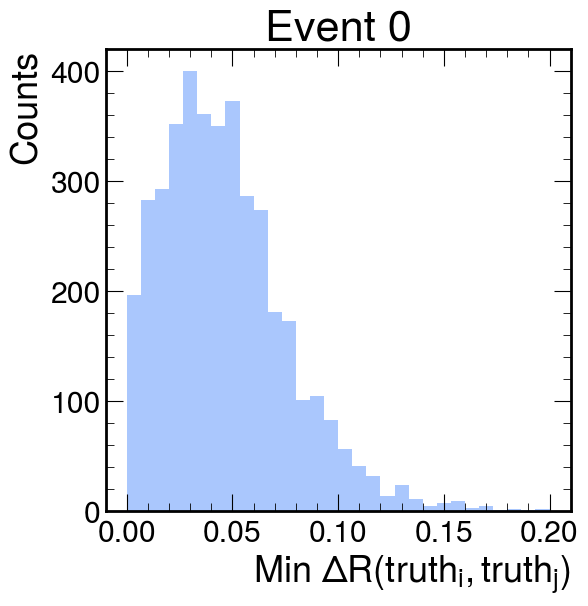

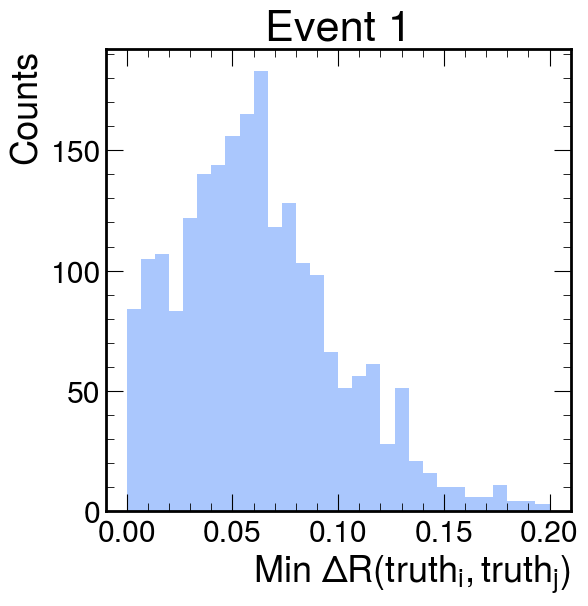

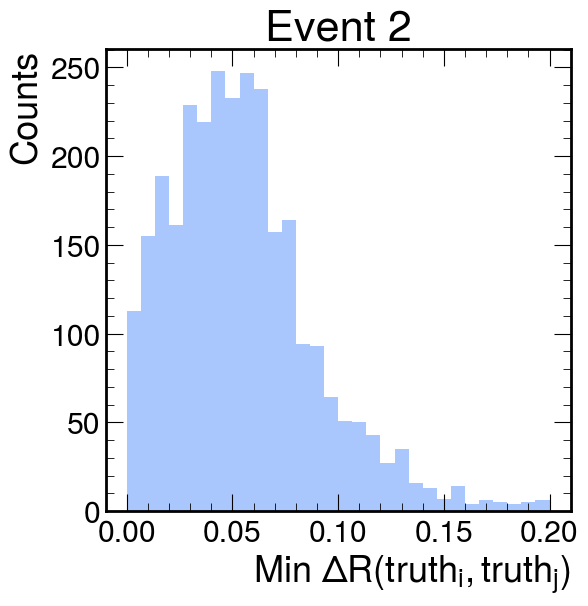

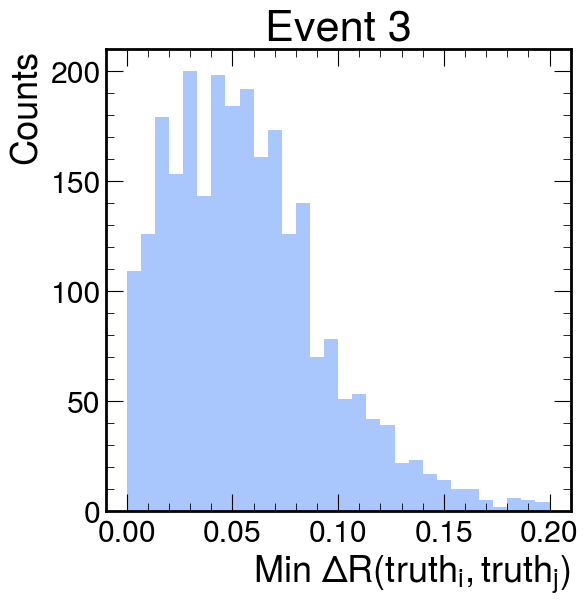

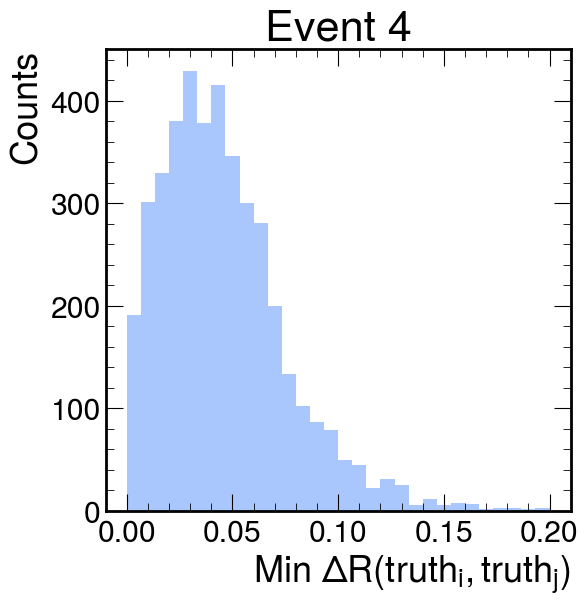

In [209]:
for ievt in range(5):
    plt.figure(figsize=(6, 6))
    plt.hist(min_dr[ievt], bins=30, alpha=0.5, range=(0, 0.2));
    plt.title(f"Event {ievt}")
    plt.xlabel("Min $\Delta R(truth_{i}, truth_{j})$")
    plt.ylabel("Counts")
    plt.show()

In [131]:
df.TruthCBToLayerCluster.TruthCBToLayerClusterLinks_index[0]

<Array [39789, 39963, 39680, ... 7611, 15724] type='52855 * uint32'>

In [141]:
df.TruthCBToLayerCluster.TruthCBToLayerCluster_nTruthCBToLayerClusterLinks[0]

<Array [20, 16, 14, 32, 30, ... 12, 27, 20, 0] type='4050 * int32'>

In [132]:
df.LayerClusterToTruthCB.LayerClusterToTruthCBLinks_index[0]

<Array [867, 9, 2961, ... 1130, 1792, 1196] type='52855 * uint32'>

In [139]:
df.LayerClusterToTruthCB.LayerClusterToTruthCB_nLayerClusterToTruthCBLinks[0]

<Array [5, 3, 1, 3, 4, 1, ... 1, 1, 1, 1, 1, 1] type='40074 * int32'>

In [155]:
df.ticlTrackstersCLUE3DHigh.fields

['ticlTrackstersCLUE3DHigh_nticlTrackstersCLUE3DHighvertices',
 'ticlTrackstersCLUE3DHigh_oticlTrackstersCLUE3DHighvertices',
 'ticlTrackstersCLUE3DHigh_barycenter_eta',
 'ticlTrackstersCLUE3DHigh_barycenter_phi',
 'ticlTrackstersCLUE3DHigh_barycenter_x',
 'ticlTrackstersCLUE3DHigh_barycenter_y',
 'ticlTrackstersCLUE3DHigh_barycenter_z',
 'ticlTrackstersCLUE3DHigh_raw_em_energy',
 'ticlTrackstersCLUE3DHigh_raw_energy',
 'ticlTrackstersCLUE3DHigh_raw_pt',
 'ticlTrackstersCLUE3DHigh_regressed_energy',
 'ticlTrackstersCLUE3DHigh_time',
 'ticlTrackstersCLUE3DHigh_timeError',
 'ticlTrackstersCLUE3DHighvertices_vertices',
 'ticlTrackstersCLUE3DHighvertices_vertex_mult']

In [162]:
df.TruthCB.fields

['TruthCB_isSignal',
 'TruthCB_hasBoundary',
 'TruthCB_pdgId',
 'TruthCB_bunchCrossing',
 'TruthCB_eventIndex',
 'TruthCB_parentGraphId',
 'TruthCB_genRootGraphId',
 'TruthCB_graphId',
 'TruthCB_levelFlags',
 'TruthCB_charge',
 'TruthCB_pt',
 'TruthCB_eta',
 'TruthCB_phi',
 'TruthCB_energy',
 'TruthCB_boundaryX',
 'TruthCB_boundaryY',
 'TruthCB_boundaryZ',
 'TruthCB_boundaryT',
 'TruthCB_boundaryPx',
 'TruthCB_boundaryPy',
 'TruthCB_boundaryPz',
 'TruthCB_boundaryE',
 'TruthCB_boundaryPt',
 'TruthCB_boundaryEta',
 'TruthCB_boundaryPhi',
 'TruthCB_simEnergyHGCAL',
 'TruthCB_isPileup',
 'TruthCB_hasHGCALHits']

In [166]:
df.LayerClusterToTruthCB.LayerClusterToTruthCB_nLayerClusterToTruthCBLinks[0]

<Array [5, 3, 1, 3, 4, 1, ... 1, 1, 1, 1, 1, 1] type='40074 * int32'>

In [167]:
df.LayerClusterToTruthCB.LayerClusterToTruthCBLinks_index[0]

<Array [867, 9, 2961, ... 1130, 1792, 1196] type='52855 * uint32'>

In [173]:
links = df.LayerClusterToTruthCB.LayerClusterToTruthCBLinks_index
lc_matched_to_truth = df.LayerCluster[links]
lc_matched_to_truth

<Array [{LayerCluster_nHits: [1, 3, ... -322]}] type='5 * {"LayerCluster_nHits":...'>

In [177]:
df.LayerClusterToTruthCB.LayerClusterToTruthCB_nLayerClusterToTruthCBLinks[0]

<Array [5, 3, 1, 3, 4, 1, ... 1, 1, 1, 1, 1, 1] type='40074 * int32'>

In [202]:
# LayerClusters associated with each TruthCB

import numpy as np
from coffea.nanoevents.methods import vector

# Build TruthCB as Lorentz vectors so that coffea's deltaR / metric_table are available
truth = ak.zip(
    {
        "pt": df.TruthCB.TruthCB_pt,
        "eta": df.TruthCB.TruthCB_eta,
        "phi": df.TruthCB.TruthCB_phi,
        "energy": df.TruthCB.TruthCB_energy,
    },
    with_name="PtEtaPhiELorentzVector",
    behavior=vector.behavior,
)

def metric_energy(obj, obj2):
    return obj.energy / (obj.energy + obj2.energy)

# deltaR of every TruthCB with every other TruthCB: shape (event, i, j)
# (metric defaults to deltaR; equivalent to metric=lambda a, b: a.delta_r(b))
dr_table = truth.metric_table(truth, metric=metric_energy)

# Exclude the self-pairs (i == j, deltaR = 0) from the minimum
idx = ak.local_index(truth, axis=1)
energy_ratio_table = ak.where(idx[:, :, None] == idx[:, None, :], np.inf, dr_table)

# For each TruthCB, index of the closest other TruthCB and the corresponding deltaR
#idx_min_dr = ak.argmin(dr_table, axis=2)
#min_dr = ak.min(dr_table, axis=2)
#idx_min_dr, min_dr
energy_ratio_table

<Array [[[inf, 0.453, 0.373, ... 0.741, inf]]] type='5 * var * var * float64'>

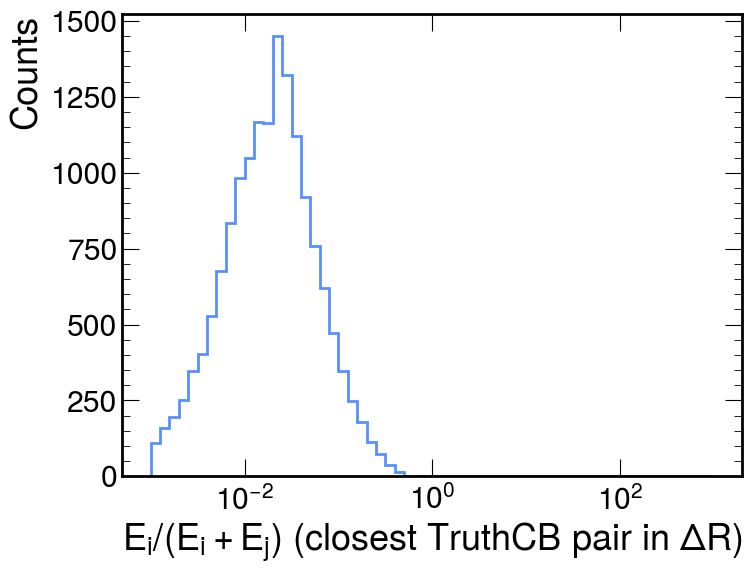

In [203]:
# Energy ratio of each TruthCB with its closest (min deltaR) other TruthCB
# keepdims=True keeps the (event, i, 1) structure so it can index the (event, i, j) table
idx_min_dr_keep = ak.argmin(dr_table, axis=2, keepdims=True)
energy_ratio_min_dr = ak.flatten(energy_ratio_table[idx_min_dr_keep], axis=2)

ratio = ak.to_numpy(ak.flatten(energy_ratio_min_dr, axis=None))

plt.figure(figsize=(8, 6))
plt.hist(ratio, bins=np.logspace(-3, 3, 61), histtype="step", linewidth=2)
plt.xscale("log")
plt.xlabel(r"$E_i / (E_i + E_j)$ (closest TruthCB pair in $\Delta R$)")
plt.ylabel("Counts")
plt.show()


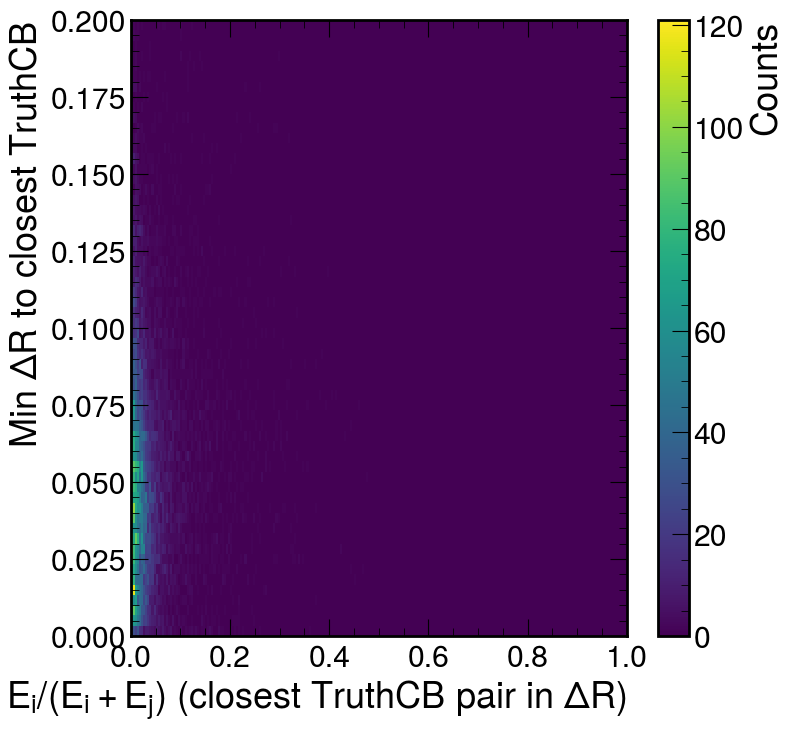

In [204]:
plt.figure(figsize=(8, 8))
plt.hist2d(ak.flatten(energy_ratio_min_dr), ak.flatten(min_dr), bins=(np.linspace(0, 1, 241), np.linspace(0, 0.2, 61)))
#plt.xscale("log")
plt.xlim(0, 1)
plt.xlabel(r"$E_i / (E_i + E_j)$ (closest TruthCB pair in $\Delta R$)")
plt.ylabel(r"Min $\Delta R$ to closest TruthCB")
plt.colorbar(label="Counts")

ValueError: x and y must have the same length.

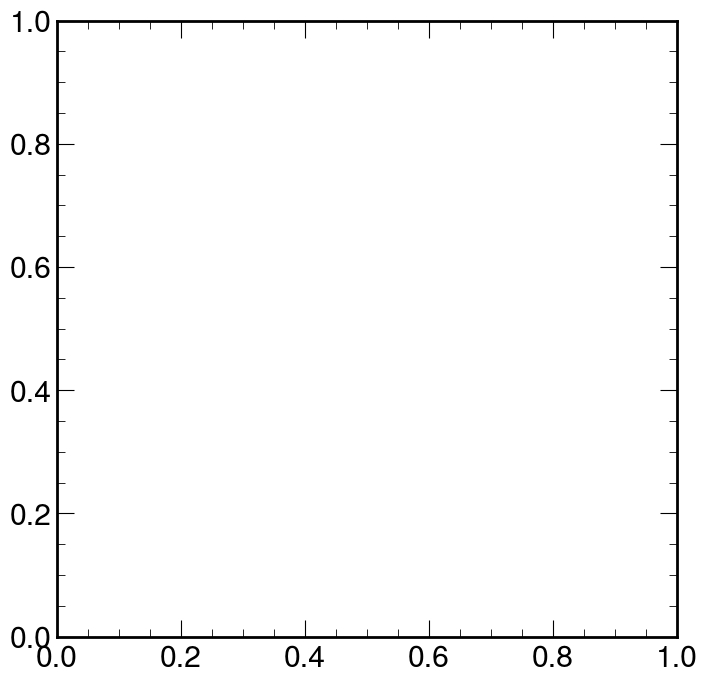

In [ ]:

plt.figure(figsize=(8, 8))
plt.hist2d(ak.flatten(energy_ratio_min_dr), ak.flatten(df.LayerCluster.LayerCluster_eta), bins=(np.linspace(0, 1, 241), np.linspace(0, 0.2, 61)))
#plt.xscale("log")
plt.xlim(0, 1)
plt.xlabel(r"$E_i / (E_i + E_j)$ (closest TruthCB pair in $\Delta R$)")
plt.ylabel(r"Min $\Delta R$ to closest TruthCB")
plt.colorbar(label="Counts")